# II - Detection Data Audit

## Objective
Inspect the detection dataset to validate its structure, image quality, duplicate samples, image-label consistency, YOLO annotations, dimensions, and bounding boxes.

## 1. Detection Dataset Configuration

The following cells import the detection audit functions, display the detection dataset location, and discover the available dataset splits.

In [6]:
import sys
import warnings
import random

import matplotlib.pyplot as plt

from PIL import Image
from pathlib import Path

warnings.filterwarnings("ignore")

In [7]:
project_root = Path.cwd().parent.parent
sys.path.insert(0, str(project_root))

In [8]:
import importlib

import src.detection.audit_data as audit_data

audit_data = importlib.reload(audit_data)

from src.detection.audit_data import (
    DETECTION_DIR,
    get_detection_splits,
    get_detection_duplicate_images,
    explore_detection_structure,
    print_detection_counts,
    print_detection_image_issues,
    validate_image_label_matching,
    validate_yolo_annotations,
    collect_detection_image_shapes,
    print_detection_image_dimensions,
    plot_detection_dimension_counts,
    plot_detection_aspect_ratios,
    display_detection_samples,
)


In [9]:
print("Detection directory:", DETECTION_DIR)
print("Detection directory exists:", DETECTION_DIR.is_dir())

Detection directory: /home/houssam/Documents/brief-5/Data/detection
Detection directory exists: True


In [10]:
detection = DETECTION_DIR
detection_splits = get_detection_splits(detection)

## 2. Detection Dataset Audit

This audit validates the detection dataset structure, image quality, duplicate samples, image-label matching, YOLO annotations, dimensions, aspect ratios, and sample bounding boxes.

### 2.1. Validate Detection Structure

This step reports the available splits and classes and checks that every class contains image and label directories.

In [11]:
explore_detection_structure(detection)

Detection directory: /home/houssam/Documents/brief-5/Data/detection
Detection directory exists: True

Number of splits: 2
Available splits: ['Train', 'Val']
Missing splits: []
Unexpected directories: []

Split: Train
Number of classes: 4
Available classes: ['Glioma', 'Meningioma', 'No Tumor', 'Pituitary']
Missing classes: []
Unexpected classes: []

  Class: Glioma
    Images directory exists: True
    Labels directory exists: True

  Class: Meningioma
    Images directory exists: True
    Labels directory exists: True

  Class: No Tumor
    Images directory exists: True
    Labels directory exists: True

  Class: Pituitary
    Images directory exists: True
    Labels directory exists: True

Split: Val
Number of classes: 4
Available classes: ['Glioma', 'Meningioma', 'No Tumor', 'Pituitary']
Missing classes: []
Unexpected classes: []

  Class: Glioma
    Images directory exists: True
    Labels directory exists: True

  Class: Meningioma
    Images directory exists: True
    Labels direc

[PosixPath('/home/houssam/Documents/brief-5/Data/detection/Train'),
 PosixPath('/home/houssam/Documents/brief-5/Data/detection/Val')]

### 2.2. Count Detection Images and Labels

This step counts supported images and YOLO label files for every class in each split.

In [12]:
print_detection_counts(detection_splits)


===== Train =====
Class: Glioma
  Supported images: 1153
  Label files: 1153
Class: Meningioma
  Supported images: 1449
  Label files: 1449
Class: No Tumor
  Supported images: 711
  Label files: 711
Class: Pituitary
  Supported images: 1424
  Label files: 1424
Total images in Train: 4737
Total labels in Train: 4737

===== Val =====
Class: Glioma
  Supported images: 136
  Label files: 136
Class: Meningioma
  Supported images: 140
  Label files: 140
Class: No Tumor
  Supported images: 100
  Label files: 100
Class: Pituitary
  Supported images: 136
  Label files: 136
Total images in Val: 512
Total labels in Val: 512

===== Dataset totals =====
Total supported images: 5249
Total label files: 5249


### 2.3. Check Detection Image Quality

This step checks supported image files, unreadable images, and unsupported files in detection image directories.

In [13]:
print_detection_image_issues(detection_splits)


===== Image quality =====
Supported image files: 5249
Unreadable images: 0
Unsupported files: 0


### 2.4. Detect Duplicate Detection Images

This check groups detection images with identical file contents using their SHA-256 hash.

Detection duplicate image groups: 1228

Detection duplicate example 1 | Hash: ce8b974baddb2dc8bac4115b3f5c9c3006cd7a0134c3722906ef5c08d3294150
  /home/houssam/Documents/brief-5/Data/detection/Train/Meningioma/images/Tr-me_0246.jpg
  /home/houssam/Documents/brief-5/Data/detection/Val/Meningioma/images/m1(168).jpg

Detection duplicate example 2 | Hash: 9f4ed340f6a7445bae80428fd41e2276da59003adeec229ae2496737b8ec2575
  /home/houssam/Documents/brief-5/Data/detection/Train/Glioma/images/Tr-gl_0036.jpg
  /home/houssam/Documents/brief-5/Data/detection/Train/Glioma/images/gg (416).jpg

Detection duplicate example 3 | Hash: aee7025a0efb6ee7c1dbabdfae17a79288e745b66ba19e840368bdd0464bf68c
  /home/houssam/Documents/brief-5/Data/detection/Train/Meningioma/images/m (23).jpg
  /home/houssam/Documents/brief-5/Data/detection/Val/Meningioma/images/Tr-me_0091.jpg

Detection duplicate example 4 | Hash: a2a1b400dfb968099b0635d36cbf5ad9b434fd1116287829cda4871501d0fe2b
  /home/houssam/Documents/brief-5/Data

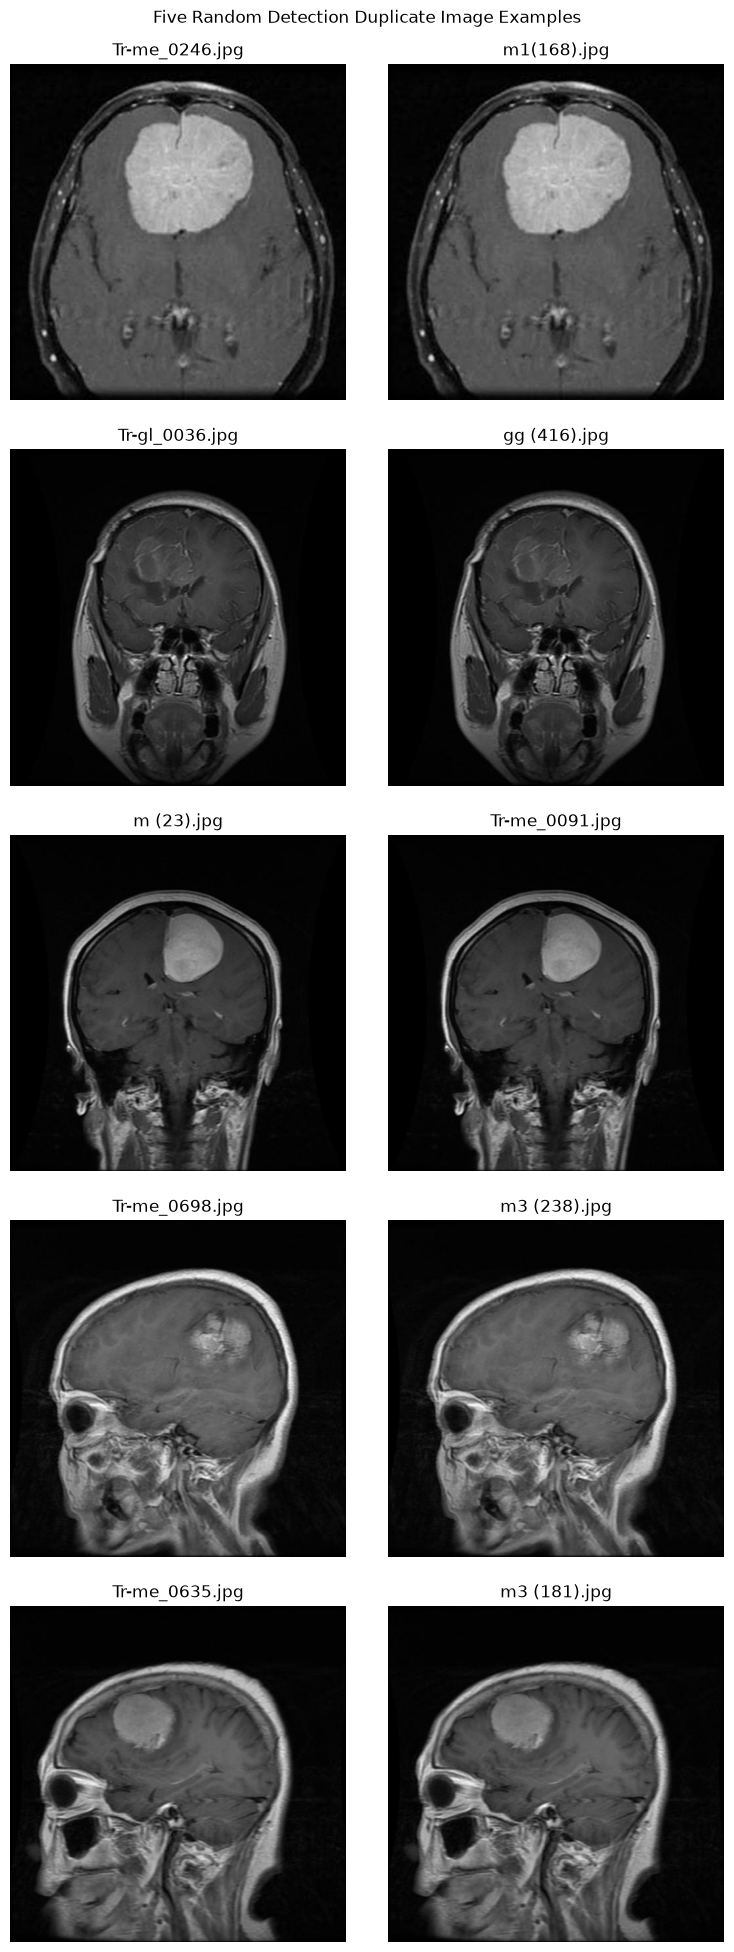

In [14]:
detection_duplicate_images = get_detection_duplicate_images(detection_splits)

print("Detection duplicate image groups:", len(detection_duplicate_images))

random.seed(42)
detection_example_groups = random.sample(
    list(detection_duplicate_images.items()),
    k=min(5, len(detection_duplicate_images)),
)

for group_number, (digest, image_paths) in enumerate(
    detection_example_groups,
    start=1,
):
    print(f"\nDetection duplicate example {group_number} | Hash: {digest}")
    for image_path in image_paths:
        print(f"  {image_path}")

if detection_example_groups:
    max_images = max(
        len(image_paths) for _, image_paths in detection_example_groups
    )
    figure, axes = plt.subplots(
        len(detection_example_groups),
        max_images,
        figsize=(4 * max_images, 4 * len(detection_example_groups)),
        squeeze=False,
    )

    for row, (digest, image_paths) in enumerate(detection_example_groups):
        for column, image_path in enumerate(image_paths):
            axes[row, column].imshow(Image.open(image_path))
            axes[row, column].set_title(image_path.name)
            axes[row, column].axis("off")

        for column in range(len(image_paths), max_images):
            axes[row, column].axis("off")

        axes[row, 0].set_ylabel(
            f"Example {row + 1}\n{digest[:12]}...",
            rotation=0,
            labelpad=45,
            va="center",
        )

    figure.suptitle("Five Random Detection Duplicate Image Examples")
    plt.tight_layout(pad=2)
    plt.show()

### 2.5. Match Images with Labels

This function finds images without matching `.txt` labels, labels without matching images, and empty label files.

In [15]:
validate_image_label_matching(detection_splits)


===== Image-label matching =====
Images without matching labels: 2
Labels without matching images: 2
Empty label files: 1

Examples: Missing labels
/home/houssam/Documents/brief-5/Data/detection/Val/No Tumor/images/image(55).jpg
/home/houssam/Documents/brief-5/Data/detection/Val/No Tumor/images/image(61).jpg

Examples: Orphan labels
/home/houssam/Documents/brief-5/Data/detection/Val/No Tumor/labels/image(53).txt
/home/houssam/Documents/brief-5/Data/detection/Val/No Tumor/labels/image(60).txt

Examples: Empty labels
/home/houssam/Documents/brief-5/Data/detection/Val/Glioma/labels/gg (342).txt


### 2.6. Validate YOLO Annotations

This function checks each label row for five numeric values, valid class IDs, normalized coordinates, and bounding boxes inside the image.

In [16]:
validate_yolo_annotations(detection_splits)


===== YOLO annotation validation =====
Valid bounding boxes: 5858
Empty label files: 1
Unreadable label files: 0
Invalid annotation lines: 15
Bounding boxes per class ID: {0: 1502, 1: 1624, 2: 796, 3: 1936}

Examples of invalid annotation lines:
/home/houssam/Documents/brief-5/Data/detection/Train/No Tumor/labels/image(318).txt:1 - Bounding box extends outside image boundaries
/home/houssam/Documents/brief-5/Data/detection/Train/No Tumor/labels/Tr-no_0988.txt:1 - Bounding box extends outside image boundaries
/home/houssam/Documents/brief-5/Data/detection/Train/No Tumor/labels/3.txt:1 - Bounding box extends outside image boundaries
/home/houssam/Documents/brief-5/Data/detection/Train/No Tumor/labels/Tr-noTr_0000.txt:1 - Bounding box extends outside image boundaries
/home/houssam/Documents/brief-5/Data/detection/Train/No Tumor/labels/image(317).txt:1 - Bounding box extends outside image boundaries
/home/houssam/Documents/brief-5/Data/detection/Train/No Tumor/labels/image(116).txt:1 - Bo

### 2.7. Collect Detection Image Dimensions

This function reads supported detection images and counts each height and width combination.

In [17]:
detection_image_shapes = collect_detection_image_shapes(detection_splits)

### 2.8. Report Detection Image Dimensions

This function prints the most common detection image sizes and the minimum and maximum dimensions.

In [18]:
print_detection_image_dimensions(detection_image_shapes)


===== Image dimensions =====
Number of unique dimensions: 325

Most common dimensions:
512 × 512: 4206 images
225 × 225: 119 images
630 × 630: 66 images
442 × 442: 42 images
236 × 236: 33 images
256 × 256: 25 images
201 × 251: 23 images
201 × 250: 22 images
214 × 236: 18 images
468 × 444: 15 images

Minimum width: 150
Maximum width: 1375
Minimum height: 168
Maximum height: 1446


### 2.9. Plot Detection Dimension Distribution

This function plots the ten most common detection image dimensions for visual comparison.

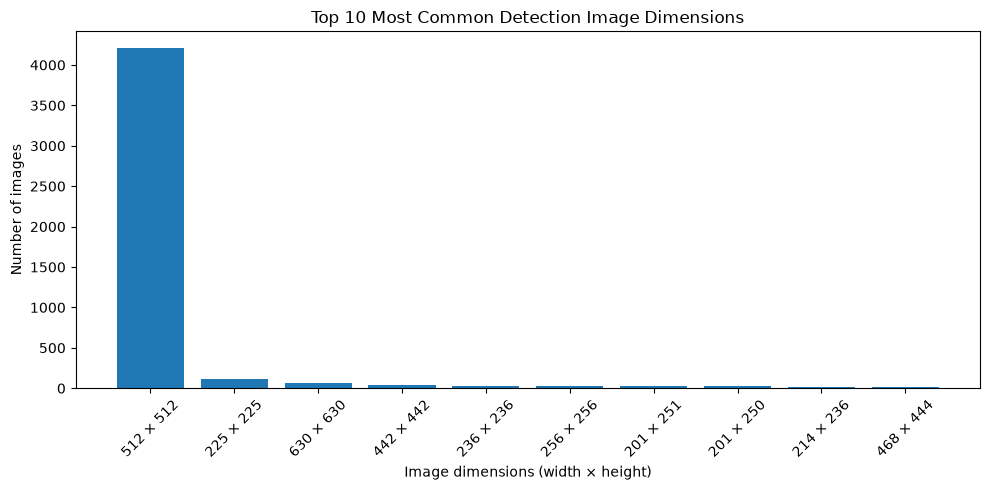

In [19]:
plot_detection_dimension_counts(detection_image_shapes)

### 2.10. Plot Detection Aspect Ratios

This function plots the width-to-height ratio distribution to identify unusually wide or tall detection images.

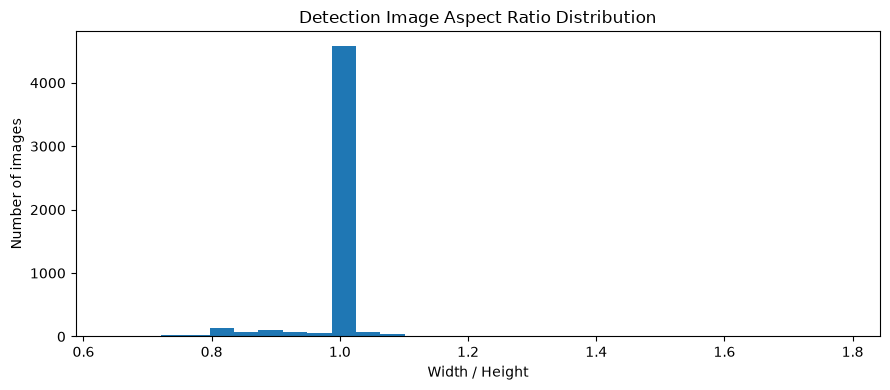

Minimum aspect ratio: 0.645
Maximum aspect ratio: 1.786


In [20]:
plot_detection_aspect_ratios(detection_image_shapes)

### 2.11. Display Detection Samples with Bounding Boxes

This function displays random images from each class and draws the YOLO bounding boxes from their label files.

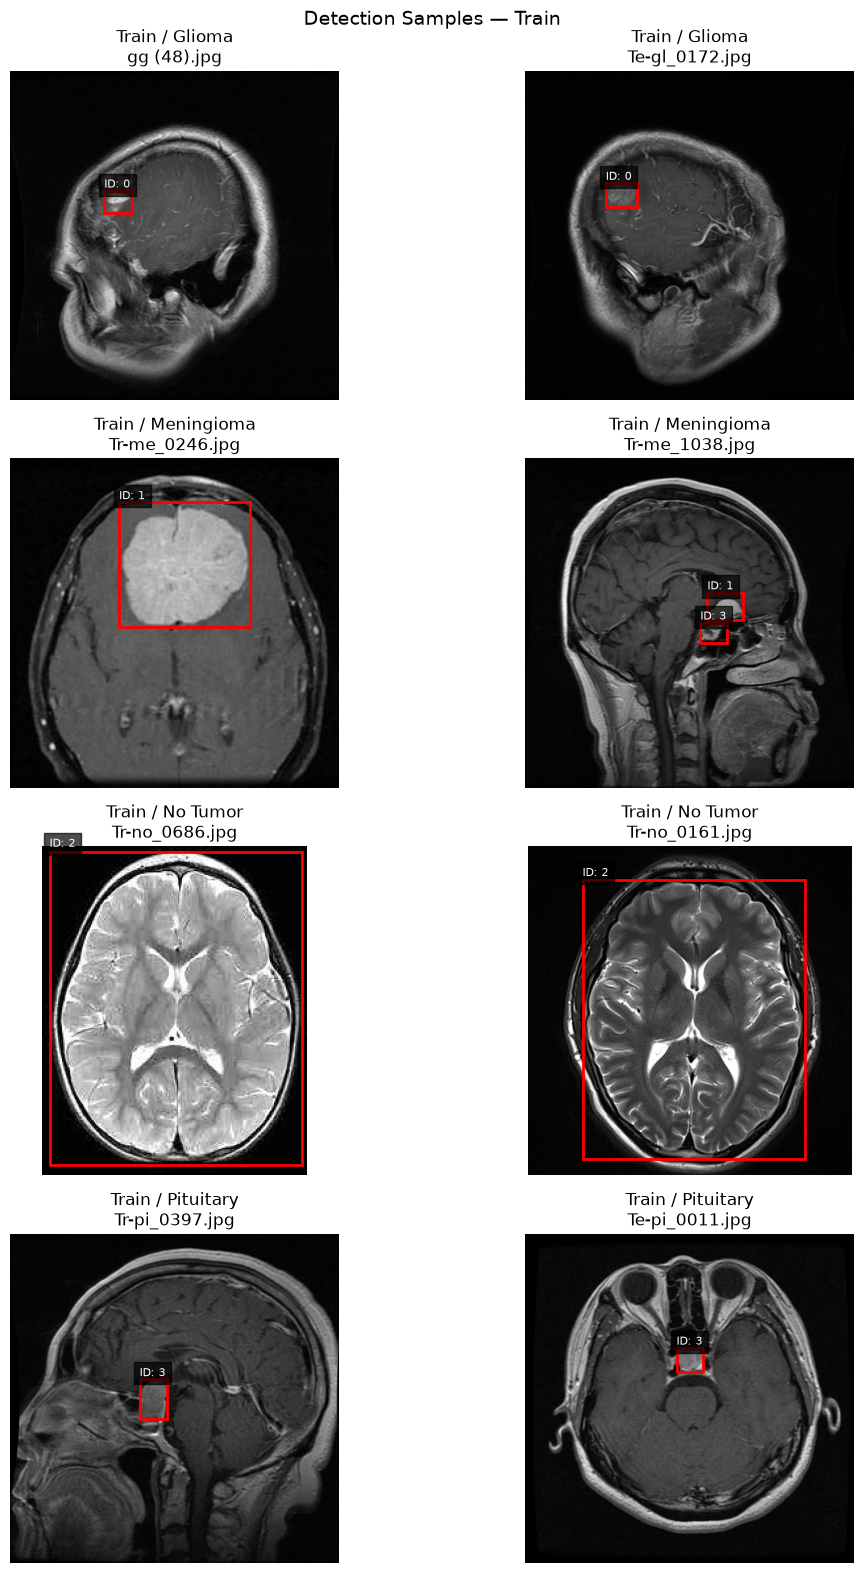

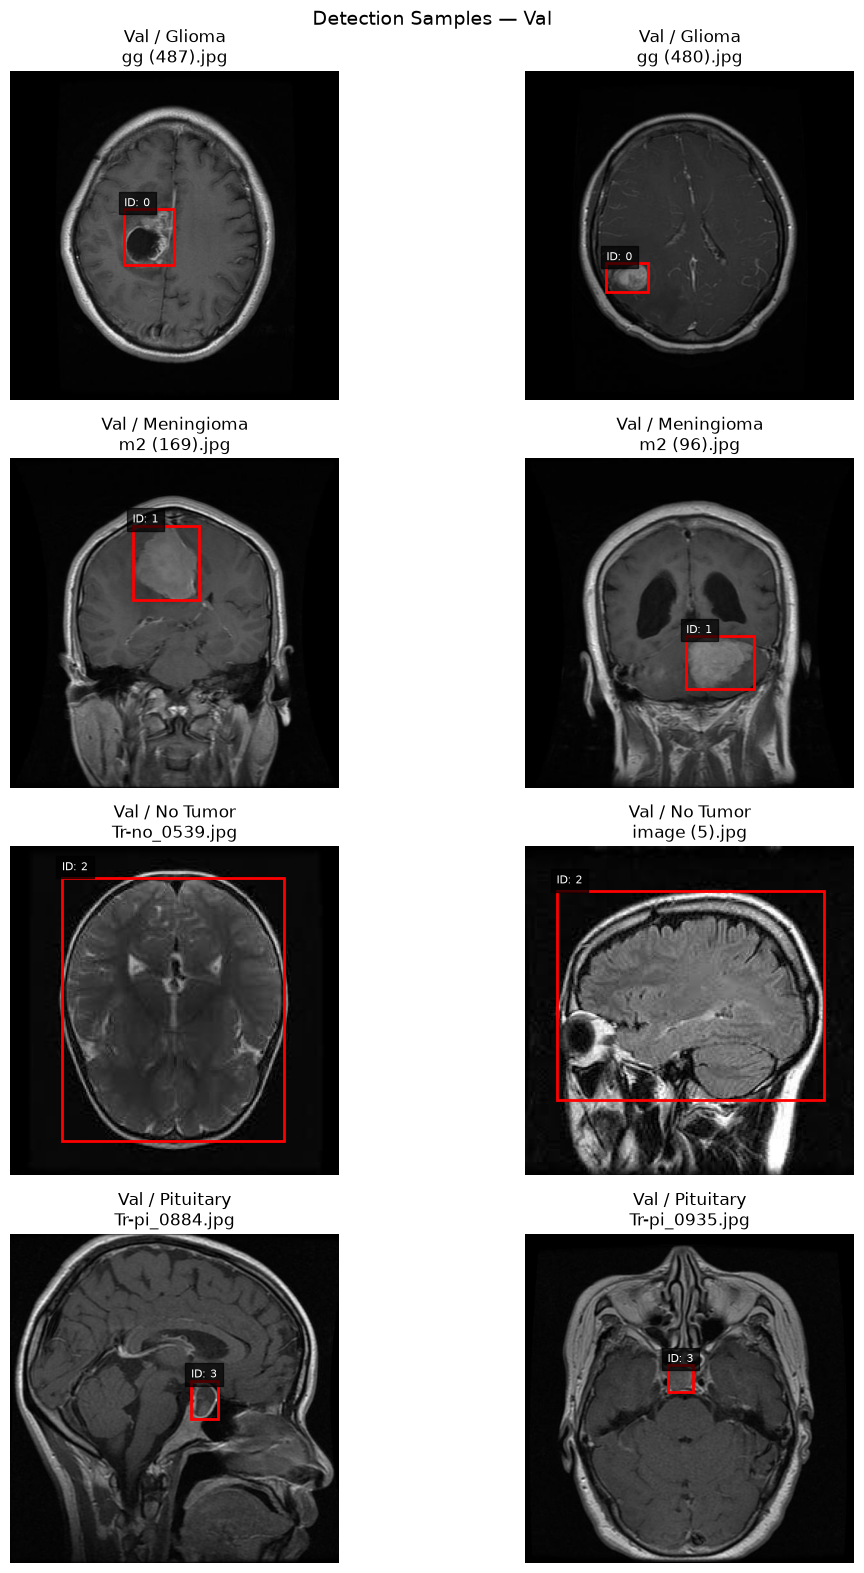

In [21]:
display_detection_samples(detection_splits)